# IDRiD — data exploration
Segmentation subset (A. Segmentation): 81 images, lesion masks for MA, HE, EX, SE + optic disc.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("../../data/raw/idrid/A. Segmentation")
IMG_DIR = ROOT / "1. Original Images"
GT_DIR = ROOT / "2. All Segmentation Groundtruths"
SPLITS = {"train": "a. Training Set", "test": "b. Testing Set"}
LESIONS = {"MA": "1. Microaneurysms", "HE": "2. Haemorrhages", "EX": "3. Hard Exudates",
           "SE": "4. Soft Exudates", "OD": "5. Optic Disc"}
COLORS = {"MA": (255, 0, 0), "HE": (0, 255, 0), "EX": (255, 255, 0), "SE": (0, 255, 255), "OD": (0, 0, 255)}

## File inventory

In [2]:
rows = []
for split, sdir in SPLITS.items():
    for img in sorted((IMG_DIR / sdir).glob("*.jpg")):
        r = {"split": split, "id": img.stem, "image": img}
        for les, ldir in LESIONS.items():
            m = GT_DIR / sdir / ldir / f"{img.stem}_{les}.tif"
            r[les] = m if m.exists() else None
        rows.append(r)
df = pd.DataFrame(rows)
print(df.groupby("split").size())
df[list(LESIONS)].notna().groupby(df["split"]).sum()

split
test     27
train    54
dtype: int64


,MA,HE,EX,SE,OD
split,,,,,
test,27,27,27,14,27
train,54,53,54,26,54


## Image sizes

In [3]:
df["size"] = [Image.open(p).size for p in df["image"]]
df["size"].value_counts()

size
(4288, 2848)    81
Name: count, dtype: int64

## Helpers

In [4]:
def load_img(p):
    return np.array(Image.open(p).convert("RGB"))

def load_mask(p):
    """Binary mask (H, W) bool. Most IDRiD tifs are 0/1 single-channel; IDRiD_81_EX is RGBA
    with alpha=255 everywhere, so only the colour channels are used."""
    m = np.array(Image.open(p))
    return (m[..., :3].max(axis=-1) if m.ndim == 3 else m) > 0

def overlay(img, masks, alpha=0.5):
    out = img.astype(float).copy()
    for les, m in masks.items():
        out[m] = (1 - alpha) * out[m] + alpha * np.array(COLORS[les])
    return out.astype(np.uint8)

print(np.unique(np.array(Image.open(df["MA"].dropna().iloc[0]))))

[0 1]


## Lesion pixel stats (fraction of image covered)

In [5]:
stats = []
for _, r in df.iterrows():
    s = {"split": r["split"], "id": r["id"]}
    for les in LESIONS:
        s[les] = load_mask(r[les]).mean() * 100 if r[les] is not None else np.nan
    stats.append(s)
stats = pd.DataFrame(stats)
stats.groupby("split")[list(LESIONS)].describe().T.round(3)

split       test   train
MA count  27.000  54.000
   mean    0.098   0.107
   std     0.053   0.086
   min     0.006   0.007
   25%     0.070   0.038
   50%     0.088   0.079
   75%     0.128   0.176
   max     0.209   0.312
HE count  27.000  53.000
   mean    1.066   1.004
   std     1.882   2.113
   min     0.023   0.018
   25%     0.204   0.220
   50%     0.530   0.478
   75%     0.886   0.856
   max     9.717  14.914
EX count  27.000  54.000
   mean    1.085   0.807
   std     1.605   1.205
   min     0.057   0.019
   25%     0.266   0.107
   50%     0.558   0.333
   75%     0.793   1.079
   max     7.510   6.594
SE count  14.000  26.000
   mean    0.349   0.393
   std     0.365   0.304
   min     0.023   0.027
   25%     0.135   0.161
   50%     0.219   0.331
   75%     0.441   0.560
   max     1.438   1.294
OD count  27.000  54.000
   mean    1.731   1.805
   std     0.298   0.326
   min     1.215   1.005
   25%     1.542   1.621
   50%     1.705   1.770
   75%     1.914   1.956
   max     2.317   2.763

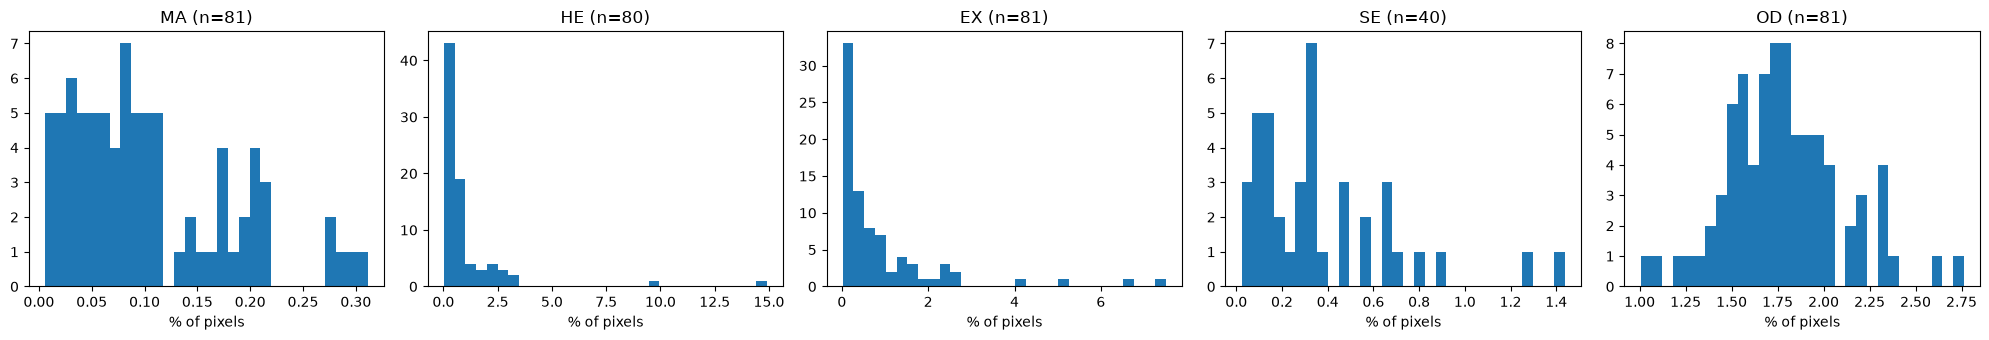

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, les in zip(axes, LESIONS):
    ax.hist(stats[les].dropna(), bins=30)
    ax.set_title(f"{les} (n={stats[les].notna().sum()})"); ax.set_xlabel("% of pixels")
plt.tight_layout(); plt.show()

## Visualise one image

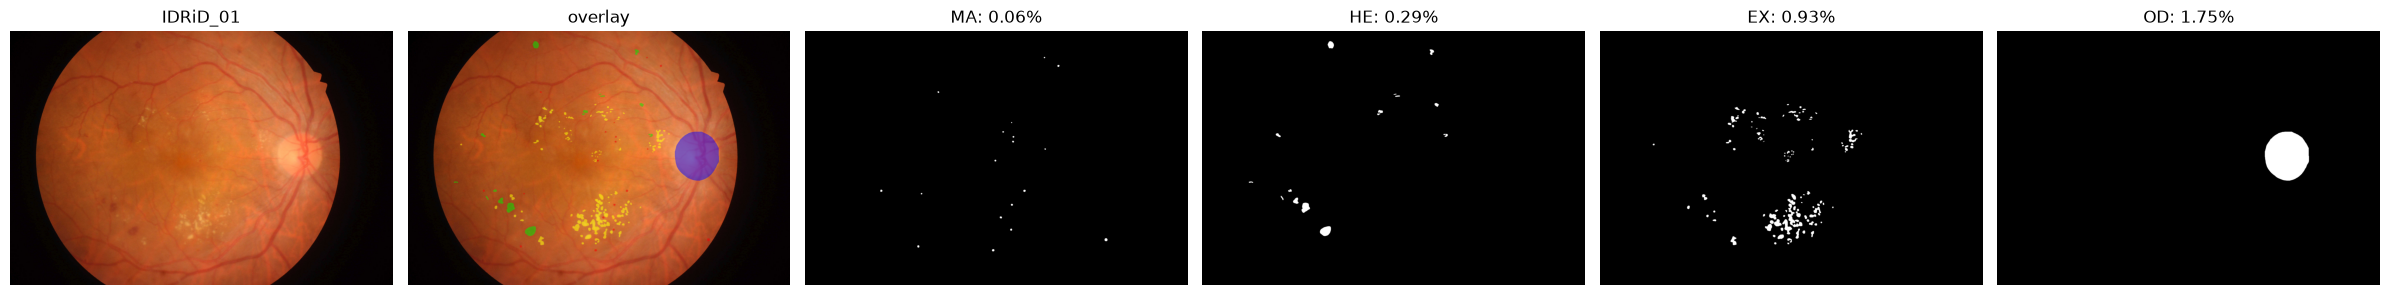

In [7]:
IDX = 0  # change to look at another image
r = df.iloc[IDX]
img = load_img(r["image"])
masks = {les: load_mask(r[les]) for les in LESIONS if r[les] is not None}

fig, axes = plt.subplots(1, 2 + len(masks), figsize=(4 * (2 + len(masks)), 4))
axes[0].imshow(img); axes[0].set_title(r["id"])
axes[1].imshow(overlay(img, masks)); axes[1].set_title("overlay")
for ax, (les, m) in zip(axes[2:], masks.items()):
    ax.imshow(m, cmap="gray"); ax.set_title(f"{les}: {m.mean()*100:.2f}%")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## Grid of overlays

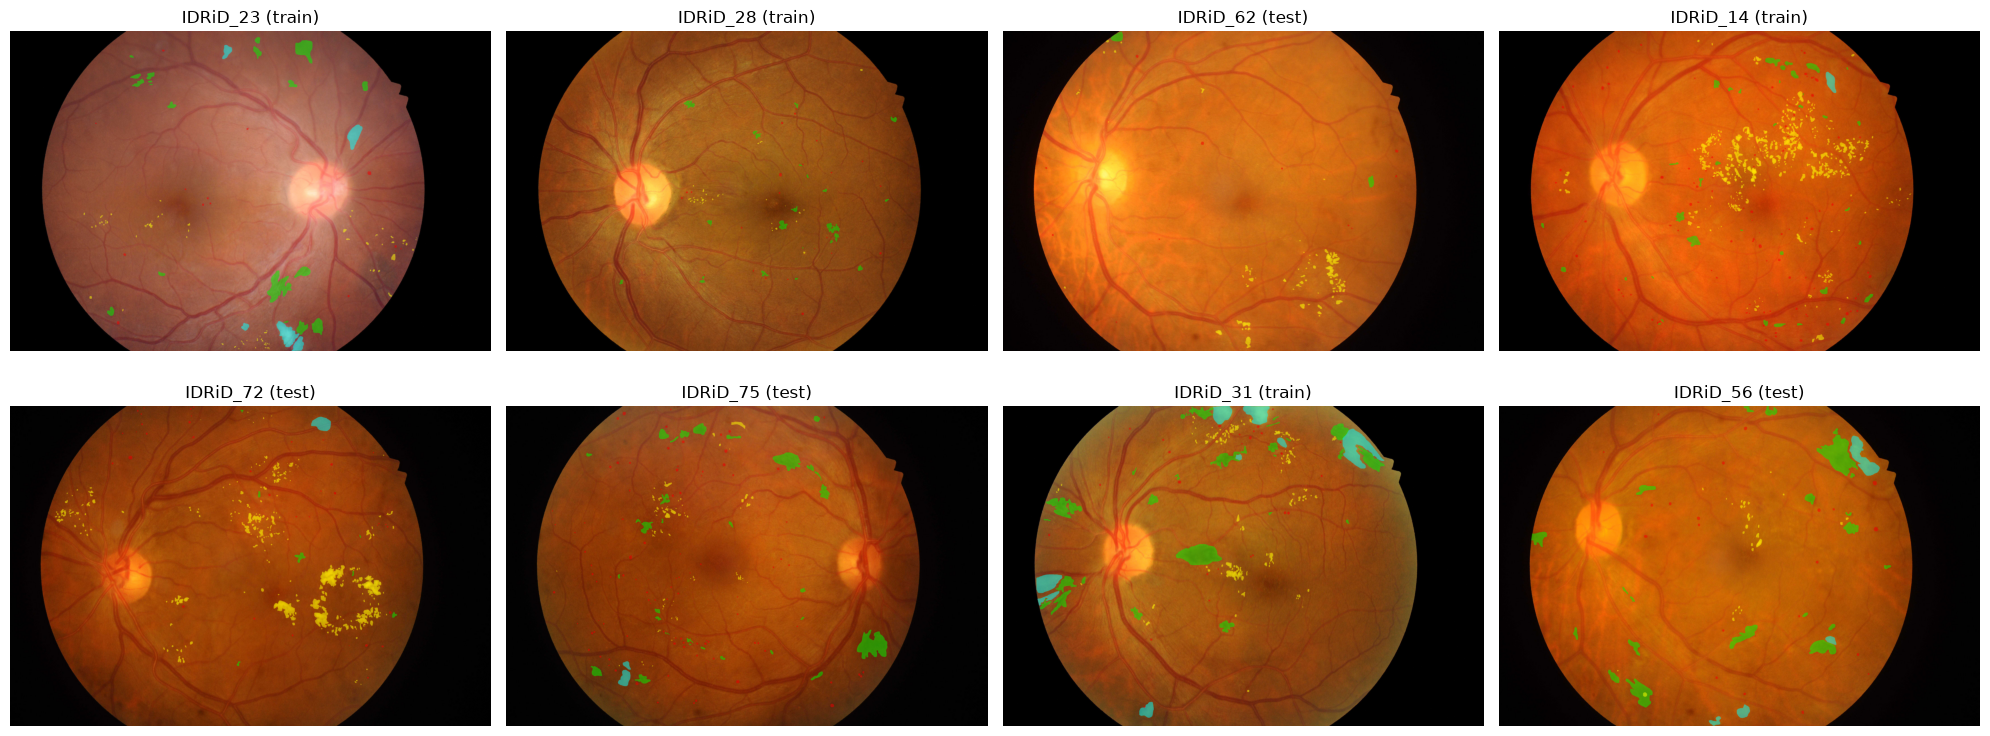

In [8]:
N = 8
sample = df.sample(N, random_state=0)
fig, axes = plt.subplots(2, N // 2, figsize=(5 * N // 2, 8))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    masks = {les: load_mask(r[les]) for les in LESIONS if r[les] is not None and les != "OD"}
    ax.imshow(overlay(load_img(r["image"]), masks)); ax.set_title(f"{r['id']} ({r['split']})"); ax.axis("off")
plt.tight_layout(); plt.show()